# 03 – Data Analysis: Ev Enerji Tüketimini İnceleme

Bu notebook'ta saatlere göre tipik tüketimi, günlük toplam tüketimleri ve yüksek tüketim dönemlerini inceleyeceğiz. Grafiklerden hareketle verideki örüntüleri yorumlayacağız.

**Ön koşul:** `energydata_complete.csv` dosyasını `data/raw/` klasörüne yerleştir. Bu çalışmada model eğitimi yapılmaz.

## 1. Kütüphaneleri ve veriyi yükle

Ortak veri yükleyici tarihleri, gerekli sütunları ve 10 dakikalık aralıkları doğrular.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from energy_forecast.data_analysis.data_loader import load_energy_data
data = load_energy_data()
data.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 2. Saatlere göre tipik tüketim

Her ölçümün saat bilgisini çıkarıp aynı saatteki `Appliances` değerlerinin ortalamasını hesaplıyoruz. Böylece günün hangi saatlerinde tüketimin tipik olarak daha yüksek olduğunu görebiliriz.

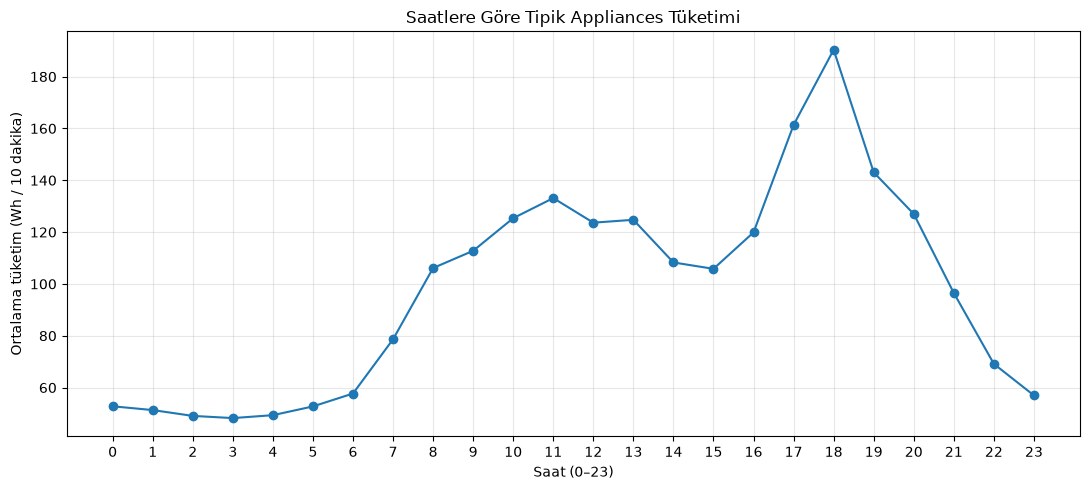

In [2]:
data["hour"] = data["date"].dt.hour
hourly_typical = data.groupby("hour")["Appliances"].mean()

plt.figure(figsize=(11, 5))
plt.plot(hourly_typical.index, hourly_typical.values, marker="o")
plt.title("Saatlere Göre Tipik Appliances Tüketimi")
plt.xlabel("Saat (0–23)")
plt.ylabel("Ortalama tüketim (Wh / 10 dakika)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Grafiği yorumla:**
- Ortalama tüketimin en yüksek olduğu saat hangisi?
- En düşük olduğu saat hangisi?
- Sabah, öğle ve akşam saatleri arasında belirgin bir fark görüyor musun?

## 3. Günlük toplam tüketimler

Her günün 10 dakikalık Wh değerlerini topluyoruz. Günlük toplamı kWh cinsinden de göstermek için 1.000'e bölüyoruz. Veri setinin ilk ve son günleri kısmi olabilir; kayıt sayısını da incele.

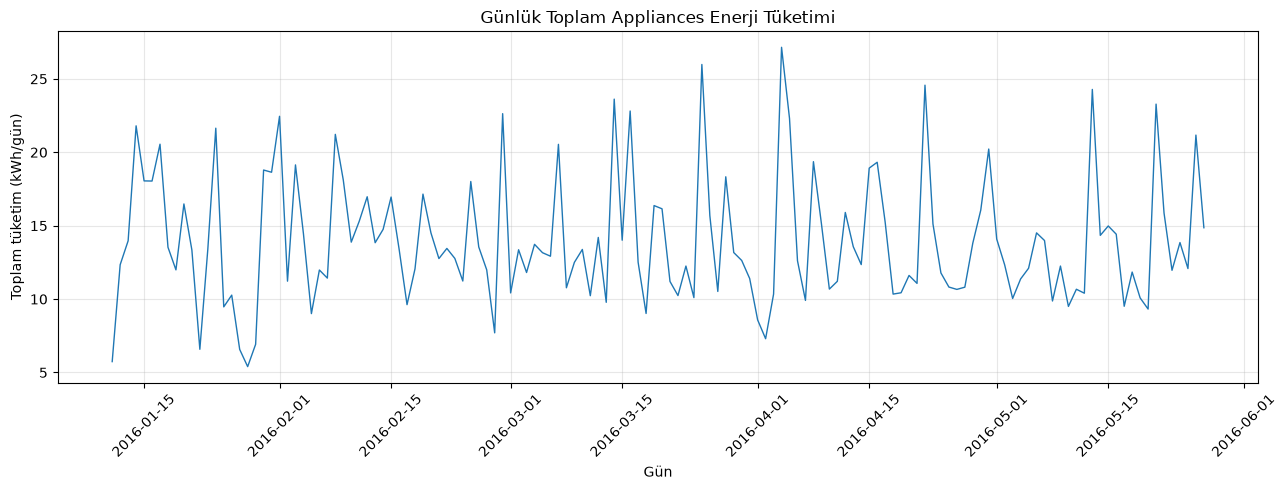

In [3]:
data["day"] = data["date"].dt.date
daily_summary = data.groupby("day").agg(
    total_wh=("Appliances", "sum"),
    measurement_count=("Appliances", "count")
)
daily_summary["total_kwh"] = daily_summary["total_wh"] / 1000

plt.figure(figsize=(13, 5))
plt.plot(daily_summary.index, daily_summary["total_kwh"], linewidth=1)
plt.title("Günlük Toplam Appliances Enerji Tüketimi")
plt.xlabel("Gün")
plt.ylabel("Toplam tüketim (kWh/gün)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Grafiği yorumla:**
- Günlük toplam tüketimin en yüksek olduğu günler hangileri?
- Günlük tüketim günler arasında ne kadar değişiyor?
- Kısmi günler toplam tüketim karşılaştırmasını nasıl etkileyebilir?

## 4. Yüksek tüketim dönemleri

Yüksek tüketim için veri setindeki `Appliances` değerlerinin 90. yüzdelik dilimini eşik olarak kullanıyoruz. Bu eşik, gözlemlerin yaklaşık en yüksek yüzde 10'luk bölümünü belirlemeye yardımcı olur; bir güvenlik veya cihaz alarm limiti değildir.

90. yüzdelik dilim eşiği: 196.00 Wh / 10 dakika
Yüksek tüketim kaydı: 1,974


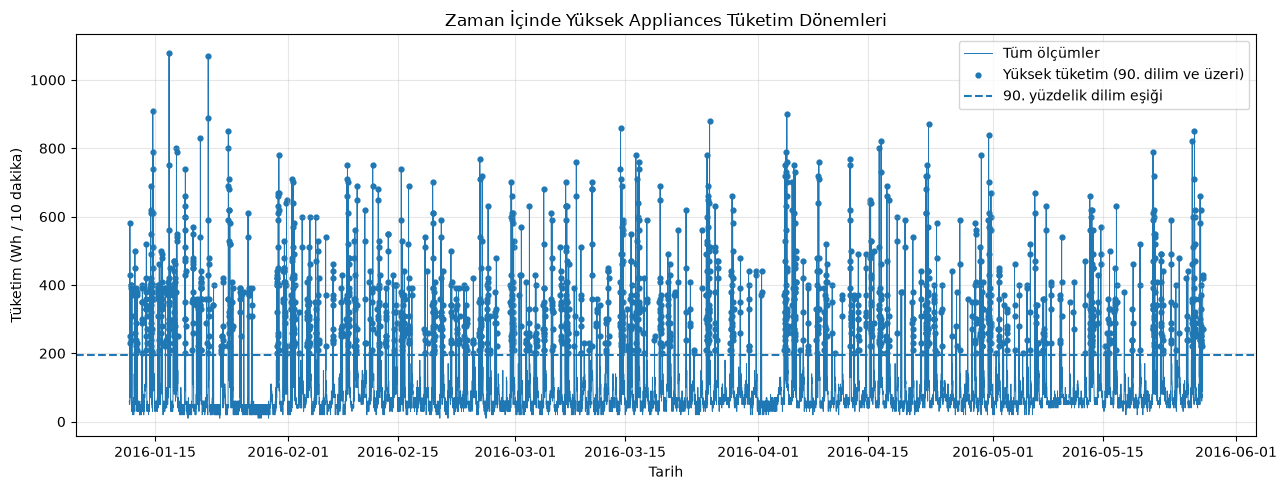

In [4]:
high_threshold = data["Appliances"].quantile(0.90)
high_usage = data[data["Appliances"] >= high_threshold].copy()

print(f"90. yüzdelik dilim eşiği: {high_threshold:.2f} Wh / 10 dakika")
print(f"Yüksek tüketim kaydı: {len(high_usage):,}")

plt.figure(figsize=(13, 5))
plt.plot(data["date"], data["Appliances"], linewidth=0.7, label="Tüm ölçümler")
plt.scatter(high_usage["date"], high_usage["Appliances"], s=12, label="Yüksek tüketim (90. dilim ve üzeri)")
plt.axhline(high_threshold, linestyle="--", label="90. yüzdelik dilim eşiği")
plt.title("Zaman İçinde Yüksek Appliances Tüketim Dönemleri")
plt.xlabel("Tarih")
plt.ylabel("Tüketim (Wh / 10 dakika)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Grafiği yorumla:**
- Yüksek tüketim noktaları belirli zamanlarda kümeleniyor mu?
- En yüksek tüketim noktaları günün hangi bölümlerinde görülüyor?
- Yüzdelik dilim eşiği ile kullanıcı tarafından belirlenen alarm eşiği arasındaki fark nedir?

## 5. Kısa değerlendirme

1. Saatlik ortalamaya bakarak tüketimin yoğunlaştığı saatleri kendi cümlelerinle özetle.
2. Günlük toplamlar arasında gözlemlediğin değişkenliğe iki olası açıklama yaz.
3. Yüksek tüketim dönemlerini incelerken yalnızca `Appliances` değerine bakmanın hangi sınırlamaları olabilir?

**Hatırlatma:** Bu notebook yalnızca keşifsel veri analizi yapar. Makine öğrenmesi veya derin öğrenme modeli eğitilmez.